In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from EEMasterDataset import y_train, y_test, X_val, y_val

In [2]:
train =  pd.read_csv("train.csv")
train.head()

,AirTemp,BuiltSurface,DistanceToWater,EVI,Elevation,LST,LandCover,Latitude,Longitude,Month,...,NDVI,NDWI,Population,Slope,TreeCover,Year,WindSpeed,Humidity,Month_sin,Month_cos
0,13.740071,5513,5218.448045,0.147212,223,17.793535,50,28.632587,77.204405,1,...,0.191410,-0.146623,190.287857,3.489779,0.120782,2021,1.056393,72.193390,0.5,0.866025
1,13.698763,4618,5018.615347,0.039060,219,18.918063,50,28.614531,77.114124,1,...,0.057639,-0.092586,318.664734,1.854334,0.033716,2021,1.003787,72.235621,0.5,0.866025
2,13.433433,0,8279.239095,0.076935,211,18.295984,80,28.783773,77.106847,1,...,0.126437,-0.081592,0.000000,1.406886,0.043828,2021,1.046076,74.763984,0.5,0.866025
3,13.556550,2576,2284.928883,0.138797,216,18.907809,50,28.660614,77.147272,1,...,0.213527,-0.175171,268.919067,2.307262,0.063085,2021,1.025128,73.834889,0.5,0.866025
4,13.413977,0,2397.185850,0.402127,226,17.137275,40,28.814496,76.991773,1,...,0.575081,-0.471949,0.000000,4.263645,0.107112,2021,0.997212,74.454896,0.5,0.866025


In [9]:
test = pd.read_csv("test.csv")
test.head()

,AirTemp,BuiltSurface,DistanceToWater,EVI,Elevation,LST,LandCover,Latitude,Longitude,Month,...,NDVI,NDWI,Population,Slope,TreeCover,Year,WindSpeed,Humidity,Month_sin,Month_cos
0,31.713791,5513,5218.448045,0.307821,223,38.650293,50,28.632587,77.204405,5,...,0.406217,-0.386133,190.287857,3.489779,0.061827,2025,1.139496,46.328039,0.5,-0.866025
1,31.870379,4618,5018.615347,0.072727,219,42.017042,50,28.614531,77.114124,5,...,0.090350,-0.114775,318.664734,1.854334,0.032390,2025,1.095888,45.640569,0.5,-0.866025
2,31.525858,0,8279.239095,0.177889,211,39.217684,80,28.783773,77.106847,5,...,0.234292,-0.289397,0.000000,1.406886,0.046423,2025,1.188778,47.583937,0.5,-0.866025
3,31.711517,2576,2284.928883,0.279416,216,41.603462,50,28.660614,77.147272,5,...,0.431262,-0.425000,268.919067,2.307262,0.056690,2025,1.144877,46.826872,0.5,-0.866025
4,31.604455,0,2397.185850,0.422223,226,40.101242,40,28.814496,76.991773,5,...,0.594331,-0.582082,0.000000,4.263645,0.146633,2025,1.140920,46.906811,0.5,-0.866025


In [12]:
val = pd.read_csv("validation.csv")
val.head()

,AirTemp,BuiltSurface,DistanceToWater,EVI,Elevation,LST,LandCover,Latitude,Longitude,Month,...,NDVI,NDWI,Population,Slope,TreeCover,Year,WindSpeed,Humidity,Month_sin,Month_cos
0,33.901950,5513,5218.448045,0.247787,223,43.423558,50,28.632587,77.204405,5,...,0.351121,-0.354582,190.287857,3.489779,0.057436,2024,0.846160,25.514994,0.5,-0.866025
1,34.043402,4618,5018.615347,0.068845,219,47.222687,50,28.614531,77.114124,5,...,0.096819,-0.162288,318.664734,1.854334,0.034247,2024,0.875322,24.895760,0.5,-0.866025
2,33.599441,0,8279.239095,0.138741,211,44.549795,80,28.783773,77.106847,5,...,0.185703,-0.222430,0.000000,1.406886,0.040705,2024,0.774359,27.103771,0.5,-0.866025
3,33.863144,2576,2284.928883,0.250491,216,47.383334,50,28.660614,77.147272,5,...,0.448656,-0.477161,268.919067,2.307262,0.054898,2024,0.829922,26.018656,0.5,-0.866025
4,33.710097,0,2397.185850,0.056590,226,52.512073,40,28.814496,76.991773,5,...,0.095137,-0.204651,0.000000,4.263645,0.029437,2024,0.814811,26.245205,0.5,-0.866025


In [13]:
TARGET = "LST"
X_train = train.drop(columns=[TARGET])
X_test = test.drop(columns=TARGET)
X_val = val.drop(columns=TARGET)

In [14]:
y_train = train[TARGET]
y_test = test[TARGET]
y_val = val[TARGET]

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [7]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Training...")

model.fit(X_train, y_train)

print("Training Complete!")

Training...
Training Complete!


In [15]:
test_pred = model.predict(X_test)

print("\nTest Results")

print("MAE :", mean_absolute_error(y_test, test_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))

print("R²  :", r2_score(y_test, test_pred))


Test Results
MAE : 1.9705257349520553
RMSE: 2.4451644283054006
R²  : 0.9091332868248163


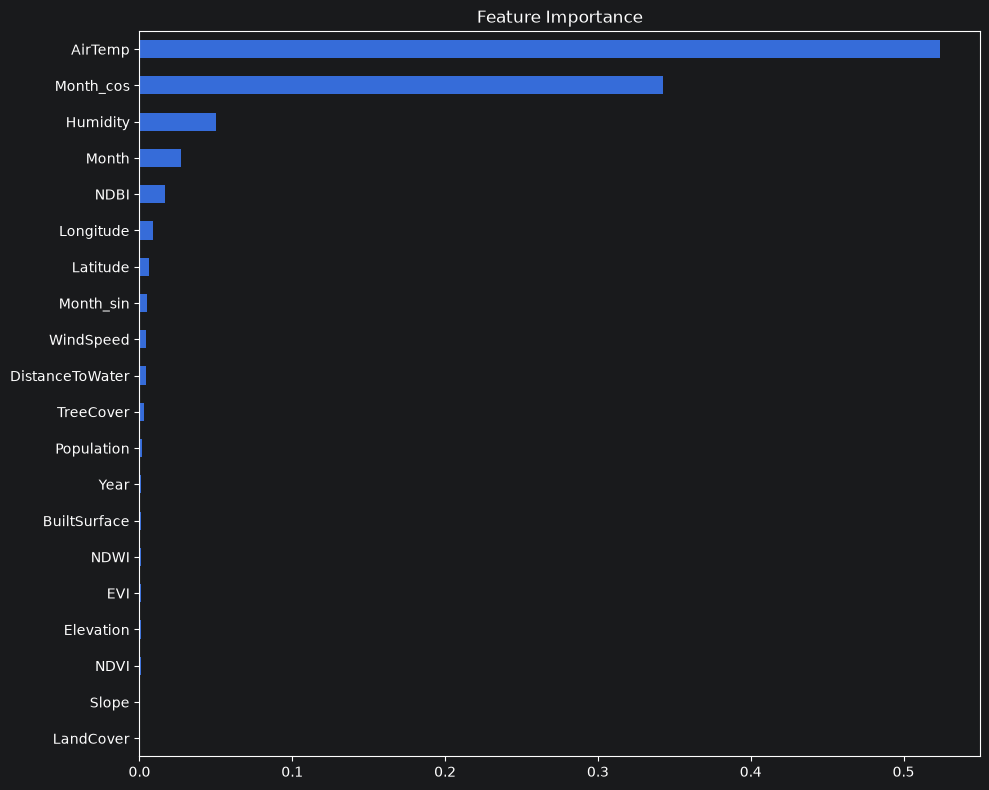

In [16]:
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(10,8))
importance.plot(kind="barh")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

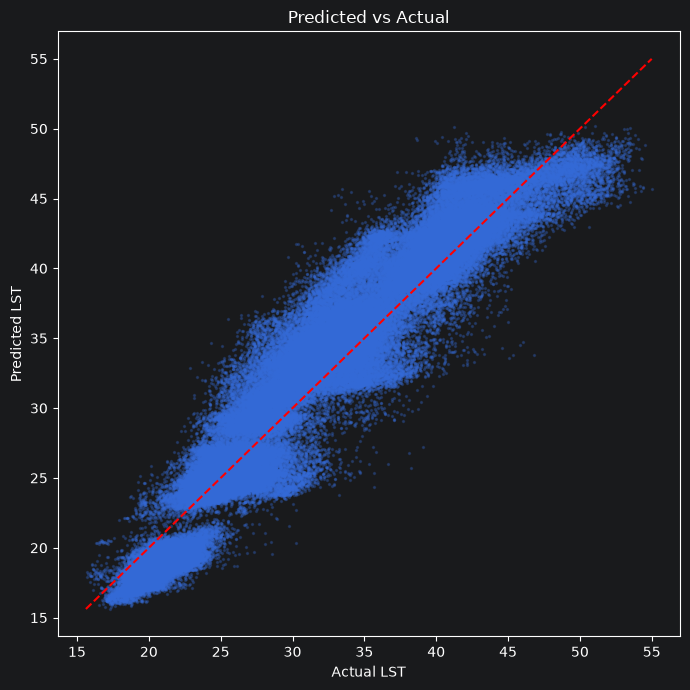

In [17]:
plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    test_pred,
    s=2,
    alpha=0.25
)

plt.xlabel("Actual LST")
plt.ylabel("Predicted LST")

xmin = min(y_test.min(), test_pred.min())
xmax = max(y_test.max(), test_pred.max())

plt.plot([xmin, xmax], [xmin, xmax], "r--")

plt.title("Predicted vs Actual")

plt.tight_layout()

plt.show()


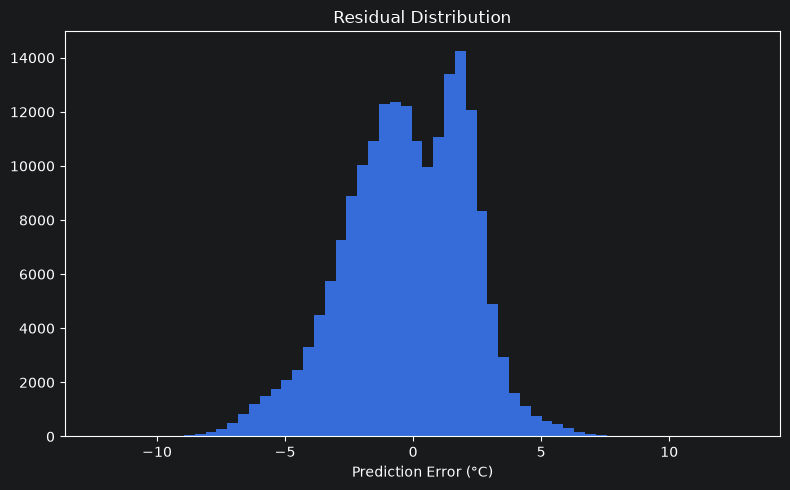

In [18]:
residuals = y_test - test_pred

plt.figure(figsize=(8,5))

plt.hist(residuals, bins=60)

plt.title("Residual Distribution")

plt.xlabel("Prediction Error (°C)")

plt.tight_layout()

plt.show()

In [19]:
joblib.dump(model, "urban_heat_rf.pkl")

print("\nModel Saved!")


Model Saved!
